# GNSS-T VOD vs rainfall interception storage — reproduce the paper's interception figure (Schellenberg et al. 2026, *Biogeosciences*)

**Paper:** Schellenberg, K., et al. (2026): *Evaluating GNSS-T VOD sensitivity to plant water dynamics, rainfall interception, and dew in a coniferous forest*, Biogeosciences 23, 8507–8536. DOI: [10.5194/bg-23-8507-2026](https://doi.org/10.5194/bg-23-8507-2026)

**Author code:** [konstantinschellenberg/eval-gnsst-vod-forest-water-content](https://github.com/konstantinschellenberg/eval-gnsst-vod-forest-water-content) @ commit `a819851a26fd70e87129e5099f4305d28a69b54f` (code supplement for EGUSPHERE-2026-1751)

**Author data:** Zenodo record [19356983](https://doi.org/10.5281/zenodo.19356983) (v0.1.0, CC BY 4.0) — postprocessed GNSS / meteorology / CanWat outputs for the DE-Tha spruce site, 2024 growing season.

## Purpose and exact scope
Run the **authors' own figure pipeline** for the **interception-storage figure group** on the minimal required input (the two analysis-ready CSVs): the 30-min scatter of vegetation optical depth (VOD) against 3-D canopy interception storage `C_3D` (`PAPER_scatter_timestep_vod_multi.png`, paper Fig. 4), the monthly development of the attenuation coefficient *b* (`paper_temporal_regressions.png`), the event-size regression summary, and the two author threshold diagnostics. Raw GNSS preprocessing, the CanWat interception re-run, and the dew / plant-water / noise figure groups are **out of scope** (their upstream pipelines are not public).

## Execution status
This notebook was **validated end-to-end on a fresh Google Colab CPU runtime** (see the validation record at the end). No GPU is used anywhere in this analysis.

**AI-note / AI注記:** The scientific code is executed **as published by the authors** (pinned commit above); the glue cells (clone, download, display) are notebook-specific and AI-assisted. No scientific routine was re-implemented.
※このノートブックは著者公開コードをそのまま実行します。クローン・ダウンロード・表示などの補助セルのみAI作成です。

**日本語概要:** 本ノートブックは、2024年生育期のドイツ・Tharandt針葉樹林（DE-Tha）におけるGNSS屈折測定（GNSS-T）から得た30分値のVODと、3次元遮断モデルCanWatによる林冠遮断貯留量 S<sub>i</sub>（`C_3D`）の関係を、著者自身の解析コードで再現します。原論文Fig. 4に相当する散布図（傾き *b* = VOD/mm、R²）、月別の *b* の推移、イベント規模別回帰表、ノイズ閾値に対する診断を出力します。

## Runtime selection and how to run

**Select `Runtime → Change runtime type → CPU` (standard, no GPU needed).** The pipeline loads two ~10.5 MB CSVs (~8,000 half-hourly rows each), fits ordinary least squares with statsmodels, and renders matplotlib figures — a pure CPU workload (verified against the author import graph: numpy / pandas / matplotlib / statsmodels only). Expected end-to-end time: roughly 5–10 minutes, dominated by the ~21 MB Zenodo download. / **実行時間の目安:** 約5〜10分（Zenodoから約21MBのCSV取得を含む）。GPUは不要で、メニューから「CPU」ランタイムを選択してください。

In [ ]:
import sys, platform
print("Python:", sys.version.split()[0], "|", platform.machine())
try:
    import numpy, pandas, matplotlib, statsmodels
    print("numpy", numpy.__version__, "| pandas", pandas.__version__,
          "| matplotlib", matplotlib.__version__, "| statsmodels", statsmodels.__version__)
except ImportError as exc:
    # Fail explicitly: the author pipeline requires these scientific packages.
    raise RuntimeError(f"Required package missing: {exc}. This notebook targets the standard Colab image.") from exc

Python: 3.13.18 | x86_64


numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0 | statsmodels 0.15.0


## 1) Fetch the author's pinned code revision

Clone the author repository **inside Colab** with a partial (blob-less) clone and check out the exact verified commit `a819851a26fd70e87129e5099f4305d28a69b54f` in detached HEAD, using a cone sparse-checkout limited to the `rainy/` package (root files `run_figures.py` / `_bootstrap.py` are always included). The checked-out commit is asserted against the pinned SHA. This mirrors the authors' documented usage (`python run_figures.py`); we deliberately skip `pip install -e .` because its declared dependency `pyqt5` is not needed — `_bootstrap.py` selects the non-interactive `Agg` matplotlib backend and the entry points need only the preinstalled scientific stack.

**日本語説明:** 著者リポジトリを部分クローンし、検証済みコミット（上記SHA）を取り出します。`pip install -e .` は依存の PyQt5 が不要なため省略し、`_bootstrap.py` が設定する Agg バックエンドで図を作成します（科学計算には影響しません）。

In [ ]:
import subprocess, pathlib

REPO_URL = "https://github.com/konstantinschellenberg/eval-gnsst-vod-forest-water-content.git"
PINNED_COMMIT = "a819851a26fd70e87129e5099f4305d28a69b54f"
repo_dir = pathlib.Path("/content/repo")

if not repo_dir.exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO_URL, str(repo_dir)],
                   check=True, timeout=600)
subprocess.run(["git", "sparse-checkout", "init", "--cone"], cwd=repo_dir, check=True, timeout=120)
subprocess.run(["git", "sparse-checkout", "set", "rainy"], cwd=repo_dir, check=True, timeout=120)
subprocess.run(["git", "fetch", "--depth", "1", "origin", PINNED_COMMIT], cwd=repo_dir,
               check=True, timeout=600)
subprocess.run(["git", "checkout", "FETCH_HEAD"], cwd=repo_dir, check=True, timeout=300)
head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=repo_dir, check=True,
                      timeout=120, capture_output=True, text=True).stdout.strip()
assert head == PINNED_COMMIT, f"Checked-out commit {head} != pinned {PINNED_COMMIT}"
print("Pinned author code checked out:", head)
print("License (repo LICENSE file): CC BY-NC 4.0; pyproject states MIT; Zenodo code record metadata states CC BY 4.0 (conflict recorded, code fetched at runtime, not redistributed).")

Pinned author code checked out: a819851a26fd70e87129e5099f4305d28a69b54f
License (repo LICENSE file): CC BY-NC 4.0; pyproject states MIT; Zenodo code record metadata states CC BY 4.0 (conflict recorded, code fetched at runtime, not redistributed).


## 2) Download the analysis-ready data from Zenodo (author-linked record)

The figure code expects the two postprocessed CSVs in `repo/data/` (names fixed by `rainy/settings/settings.py`, experiment id `20260215_0955`): the **masked** file (inverted-cone GNSS footprint) and the **unmasked** file (equivalent-ground-area column). We query the Zenodo record API at runtime, download the three files by their exact record-file names through the API-returned content links, and verify every file against the record's published **MD5 checksum**. The small `variable_description.csv` is kept beside the notebook as the variable dictionary (not placed in `data/`, since the author code expects only the two CSVs there).

**日本語説明:** 論文関連のZenodoレコード 19356983 から、著者コードが要求する2つのCSV（コーン型フットプリント: masked、円柱等価: unmasked）と変数説明CSVを取得し、レコード公開のMD5で検証します。

In [ ]:
import json, hashlib, urllib.request, shutil

ZENODO_RECORD = "19356983"
api_url = "https://zenodo.org/api/records/" + ZENODO_RECORD
with urllib.request.urlopen(api_url, timeout=120) as resp:
    record = json.load(resp)
meta = record["metadata"]
print("Zenodo record:", record["doi"], "| version", meta["version"],
      "| license", meta["license"]["id"], "| access", meta["access_right"])
assert meta["access_right"] == "open", "Record is not open access."

EXPECTED_MD5 = {
    "Meteo-GNSS-Canwat_20260215_0955_postprocessed_masked.csv": "ae40c1696fbddb15940e73e6c68ceaeb",
    "Meteo-GNSS-Canwat_20260215_0955_postprocessed.csv": "076d8287dbe32dca2eb99572796d4c27",
    "variable_description.csv": "5fc06271b3e81172eadb93003db14f08",
}
data_dir = repo_dir / "data"; data_dir.mkdir(exist_ok=True)
zenodo_dir = pathlib.Path("/content/zenodo"); zenodo_dir.mkdir(exist_ok=True)

files = {f["key"]: f for f in record["files"]}
assert set(EXPECTED_MD5) <= set(files), f"Record files {sorted(files)} do not match required set"
for key in EXPECTED_MD5:
    dest = (data_dir / key) if key.startswith("Meteo") else (zenodo_dir / key)
    if not dest.exists():
        print("Downloading", key, f"({files[key]['size']:,} B) ...")
        with urllib.request.urlopen(files[key]["links"]["self"], timeout=300) as r, open(dest, "wb") as out:
            shutil.copyfileobj(r, out)
    digest = hashlib.md5(dest.read_bytes()).hexdigest()
    assert digest == EXPECTED_MD5[key], f"MD5 mismatch for {key}: {digest}"
    print(f"{key}: {dest.stat().st_size:,} B, md5 OK")

Zenodo record: 10.5281/zenodo.19356983 | version 0.1.0 | license cc-by-4.0 | access open


Meteo-GNSS-Canwat_20260215_0955_postprocessed_masked.csv: 10,508,844 B, md5 OK


Meteo-GNSS-Canwat_20260215_0955_postprocessed.csv: 10,556,869 B, md5 OK


variable_description.csv: 7,098 B, md5 OK


## 3) Preview the actual input data

Load the masked (cone-footprint) CSV and inspect it before any analysis: dimensions, time range, the author-named columns this pipeline uses (`event_number`, `VOD_idx_dry` — the dry-period indexed VOD defined in `rainy/user_code/models/standard_parameters.py` —, `C_3D` interception storage, `P_100` precipitation), plus a season overview plot of daily-mean VOD and interception storage. This overview is an **additional visualization created for this notebook**, not a paper figure. Byte-level validity has already been established by the MD5 checks above.

**日本語説明:** ダウンロードしたCSV（コーン型フットプリント）の規模・期間・列名を確認し、VODと遮断貯留量の季節変化を概観します（この概観図は本ノートブック独自の追加可視化です）。

rows: 8,305 | columns: 94 | half-hourly 2024-04-25 01:00:00+01:00 .. 2024-10-15 01:00:00+01:00
units: VOD_idx_dry dimensionless VOD; C_3D in mm (CanWat 3-D canopy storage); P_100 in mm per 30 min


,event_number,VOD_idx_dry,C_3D,P_100
count,1469.000000,1458.000000,8086.000000,8203.000000
mean,42.718856,0.095462,0.103828,0.050677
min,1.000000,-0.088630,0.000000,0.000000
max,72.000000,0.327292,2.001222,13.700000


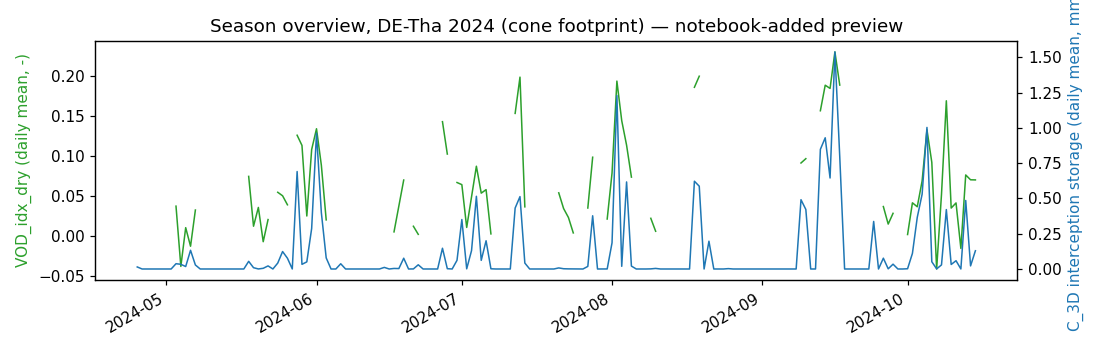

In [ ]:
import io
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

masked_path = repo_dir / "data" / "Meteo-GNSS-Canwat_20260215_0955_postprocessed_masked.csv"
df_raw = pd.read_csv(masked_path, parse_dates=[0], index_col=0).sort_index()
df_raw.name = "cone"

REQUIRED = ["event_number", "VOD_idx_dry", "C_3D", "P_100"]
missing = [c for c in REQUIRED if c not in df_raw.columns]
assert not missing, f"Required author columns missing: {missing}; inspect variable_description.csv"
print(f"rows: {len(df_raw):,} | columns: {len(df_raw.columns)} | half-hourly {df_raw.index.min()} .. {df_raw.index.max()}")
print("units: VOD_idx_dry dimensionless VOD; C_3D in mm (CanWat 3-D canopy storage); P_100 in mm per 30 min")
display(df_raw[REQUIRED].describe().loc[["count", "mean", "min", "max"]])

daily = df_raw[["VOD_idx_dry", "C_3D"]].resample("D").mean()
fig, ax1 = plt.subplots(figsize=(10, 3.2))
ax1.plot(daily.index, daily["VOD_idx_dry"], color="tab:green", lw=1)
ax1.set_ylabel("VOD_idx_dry (daily mean, -)", color="tab:green")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["C_3D"], color="tab:blue", lw=1)
ax2.set_ylabel("C_3D interception storage (daily mean, mm)", color="tab:blue")
ax1.set_title("Season overview, DE-Tha 2024 (cone footprint) — notebook-added preview")
fig.autofmt_xdate(); fig.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=110)
plt.close(fig)
display(Image(data=buf.getvalue()))

## 4) Run the authors' interception figure pipeline

Execute the authors' entry point exactly as documented in the repository README — `python run_figures.py interception` — via a checked subprocess from the repo root. This single author entry point performs: (a) the 30-min origin regression scatter `VOD = b·S_i` (`scatter_timestep_vod_vs_C3D.png`), (b) the three-panel paper figure Pg / S_i(cone) / S_i(cylinder) with event-scale regressions and 95% CI bands (`PAPER_scatter_timestep_vod_multi.png`, paper Fig. 4), (c) monthly windowed regressions of *b* (`paper_temporal_regressions.png`), (d) the event-size regression summary table, (e) the printed threshold diagnostics (shares of interception instances below the 30-min 0.37 mm and 6 h 0.28 mm detectability thresholds), and (f) two event histograms. The full author stdout is kept for the summary cells; we assert that no `ERROR` marker was emitted.

**日本語説明:** 著者リポジトリのREADMEどおり `python run_figures.py interception` を実行します。Fig. 4に相当する散布図、月別 *b*、イベント規模別回帰表、ノイズ閾値診断、ヒストグラムがまとめて生成されます。

In [ ]:
import subprocess, sys

result = subprocess.run(
    [sys.executable, "run_figures.py", "interception"],
    cwd=repo_dir, capture_output=True, text=True, timeout=1800,
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
result.check_returncode()
author_output = result.stdout
assert "ERROR" not in author_output, "Author pipeline reported an ERROR; inspect the trace above."
print("\n[summary] Author pipeline completed without errors.")

Bootstrap loaded. FIGDIR=/content/repo/figures, backend=Agg
Generating figures for: ['interception']


  PAPER: Scatter interception multi

[vod_interception] Load data
[vod_interception] Saved timestep scatter with regression: /content/repo/figures/rainy/user_code/experiments/results_interception/scatter_timestep_vod_vs_C3D.png
[vod_interception] Saved multi-panel VOD scatter figure: /content/repo/figures/rainy/user_code/experiments/results_interception/PAPER_scatter_timestep_vod_multi.png
[vod_interception] Saved temporal regression summary figure: /content/repo/figures/rainy/user_code/experiments/results_interception/paper_temporal_regressions.png
[vod_interception] Temporal regression summary (month-wise mean ± SE):
        coef             rmse               r2          
        mean sem count   mean sem count   mean sem count
month                                                   
5      0.112 NaN     1  0.049 NaN     1  0.461 NaN     1
6      0.137 NaN     1  0.048 NaN     1  0

## 5) Inspect the generated paper figure

Display the reproduced paper figure (`PAPER_scatter_timestep_vod_multi.png`, paper Fig. 4): panel (a) 30-min VOD vs gross precipitation, panels (b)/(c) 30-min VOD vs CanWat interception storage `S_i` for the cone and column footprint geometries — each with black 30-min points, blue event-scale means, the no-intercept OLS fit `VOD = b·S_i` and its 95% confidence band, and the author's noise-threshold annotations. Then list all figures written to `figures/`.

**日本語説明:** 再現したFig. 4相当図を表示します。黒点が30分値、青点がイベント平均、青線が原点回帰 VOD = b·S_i（95%信頼帯付き）です。

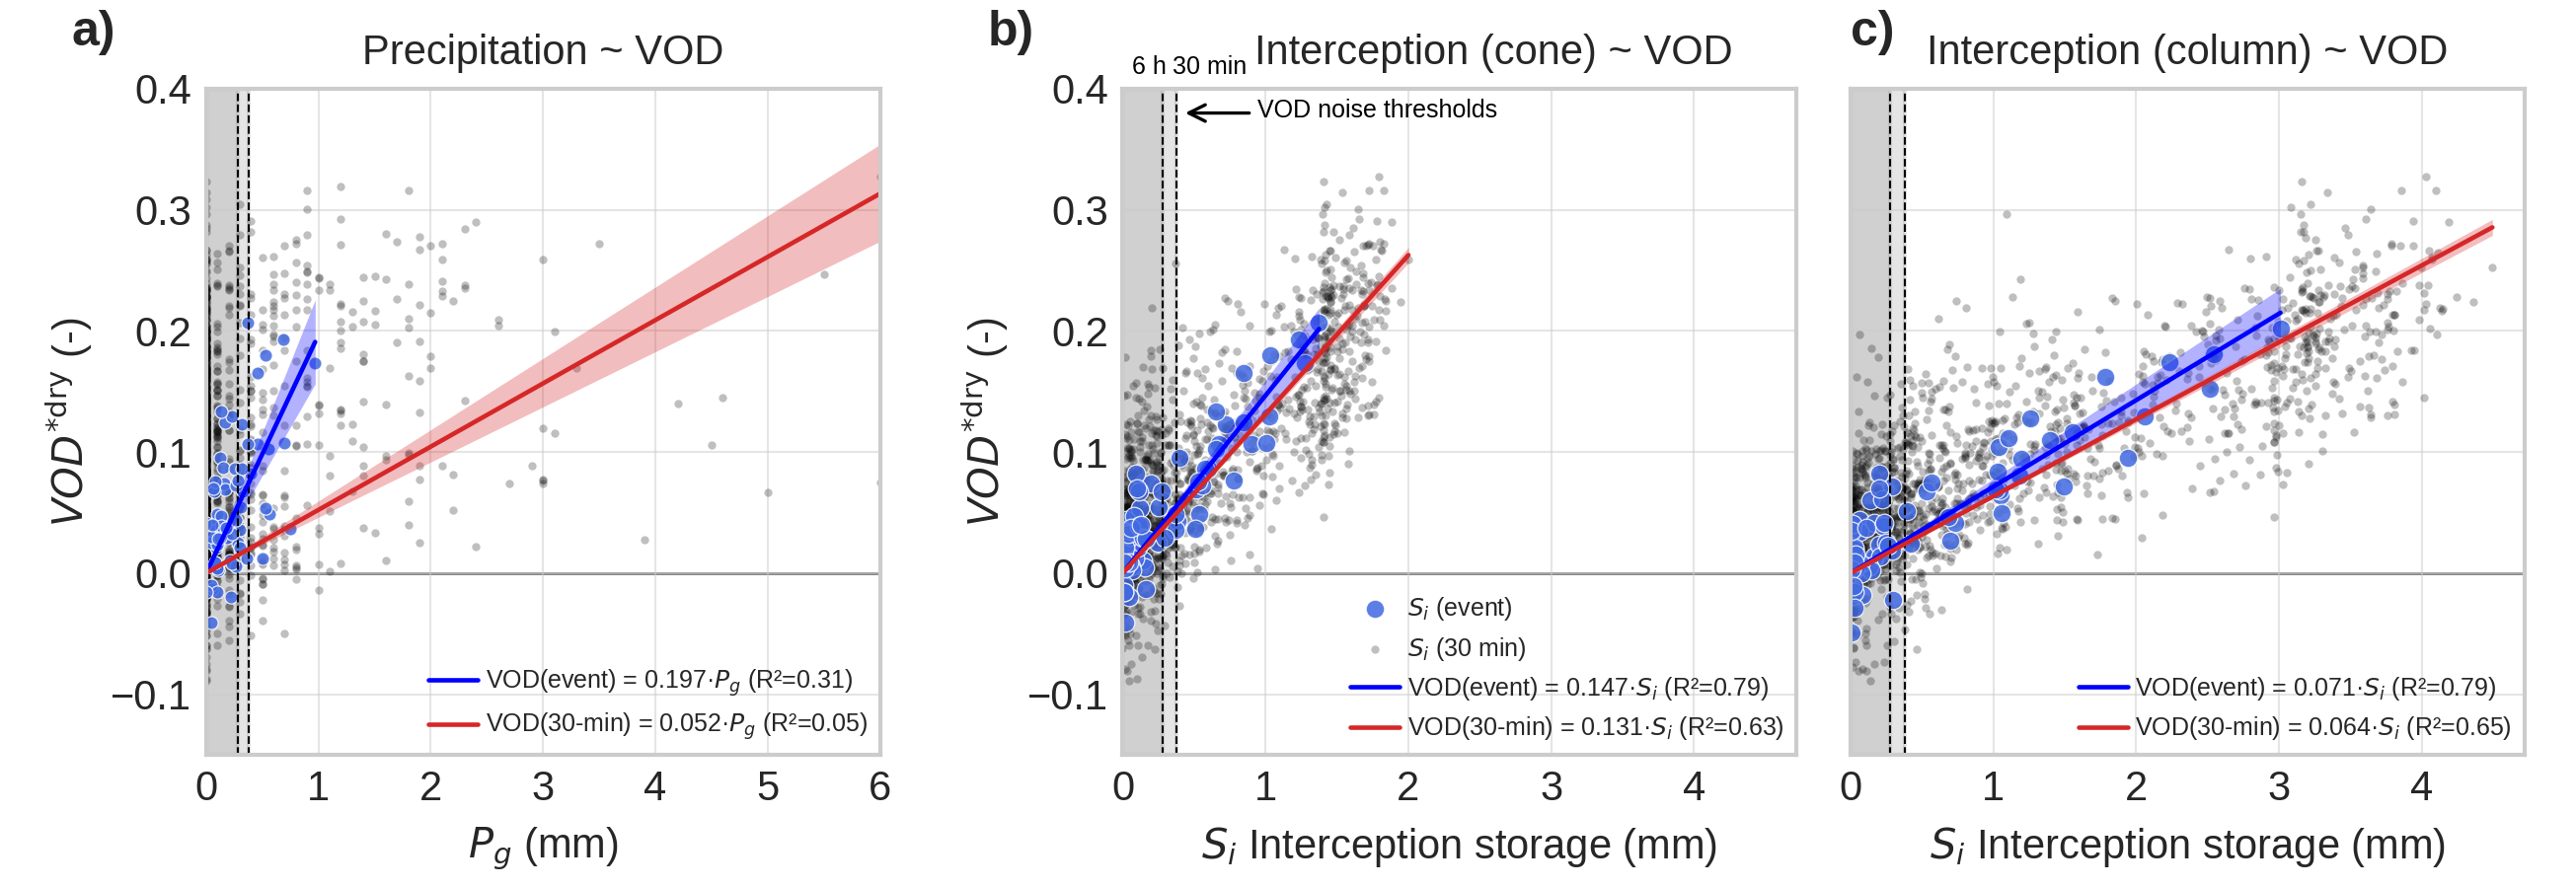


All figures generated by the author pipeline:
  figures/rainy/user_code/experiments/results_interception/PAPER_scatter_timestep_vod_multi.png  (395,305 B)
  figures/rainy/user_code/experiments/results_interception/hist_event_means.png  (97,286 B)
  figures/rainy/user_code/experiments/results_interception/hist_event_sums.png  (69,505 B)
  figures/rainy/user_code/experiments/results_interception/paper_temporal_regressions.png  (76,250 B)
  figures/rainy/user_code/experiments/results_interception/scatter_timestep_vod_vs_C3D.png  (181,468 B)


In [ ]:
from IPython.display import Image, display

fig_dir = repo_dir / "figures" / "rainy" / "user_code" / "experiments" / "results_interception"
paper_fig = fig_dir / "PAPER_scatter_timestep_vod_multi.png"
assert paper_fig.exists(), f"Expected paper figure not found at {paper_fig}"
display(Image(filename=str(paper_fig)))
print("\nAll figures generated by the author pipeline:")
for p in sorted(fig_dir.glob("*.png")):
    print(f"  {p.relative_to(repo_dir)}  ({p.stat().st_size:,} B)")

## 6) Event-size regression summary and threshold diagnostics

Show the author pipeline's event-size regression table (no-intercept OLS slopes of VOD on `S_i` at 30-min and event scales, stratified by precipitation-event size class, for both footprint geometries) and the printed shares of interception instances/events falling below the VOD noise thresholds (0.37 mm at 30-min, 0.28 mm at 6 h aggregation, from `rainy/user_code/experiments/results_interception/settings.py` and the diagnostics in `run_storage_scatter.py`). The table is the author's own LaTeX-formatted output, printed verbatim from the captured stdout.

**日本語説明:** 著者パイプラインが出力したイベント規模別回帰表と、VODノイズ閾値（30分0.37 mm、6時間0.28 mm）未満の割合の診断結果を表示します。

In [ ]:
import re

start = author_output.find("\\begin{table}")
end = author_output.find("\\end{table}") + len("\\end{table}")
if start != -1 and end > start:
    print(author_output[start:end])
else:
    print(author_output[author_output.find("[vod_interception] Load data"):])
print("\n--- detectability diagnostics (author stdout) ---")
for line in author_output.splitlines():
    if "threshold" in line.lower() and "%" in line:
        print(line)

\begin{table}[t]
\centering
\caption{\textbf{Regression slopes of VOD on interception storage $S_i$ at 30-min and event-scale aggregation.} Linear models were fit without an intercept. $R^{2}$ values are computed as the squared Pearson correlation between observed and predicted VOD, $\mathrm{cor}(y,\hat y)^2$, because the conventional ANOVA-based $R^{2}$ does not apply to models without an intercept.}
\begin{tabular}{llcccc}\toprule 
GNSS footprint & Scale & $b$ [95\% CI] (VOD/mm) & RMSE & $R^{2}$ & $N$ \\ \midrule

\multirow{2}{*}{cone} & 30 min & 0.131 [0.128, 0.135] & 0.051 & 0.634 & 1388 \\
 & event & 0.149 [0.135, 0.163] & 0.025 & 0.807 & 69 \\
\midrule
\multirow{2}{*}{cylinder} & 30 min & 0.064 [0.062, 0.065] & 0.051 & 0.654 & 1611 \\
 & event & 0.073 [0.065, 0.080] & 0.026 & 0.797 & 69 \\
\bottomrule\end{tabular}
\end{table}

--- detectability diagnostics (author stdout) ---
Percentage of interception instances with C_3D > 0 that are below the 30-min threshold (0.37 mm): 50.32%


## 7) Plausibility cross-check against the paper's reported values

Recompute the season-wide cone-footprint slopes using the **authors' own** regression function (`_origin_regression_stats`, statsmodels OLS without intercept, R² = cor(y, ŷ)²) at 30-min and event scales, and compare against the values reported in the paper / study flow: b ≈ 0.131 VOD/mm (30-min, R² ≈ 0.63), b ≈ 0.149 (event, R² ≈ 0.81), and a column slope of roughly half the cone value. This is a plausibility check of a single reproduction, not a verification of dataset-level accuracy.

**日本語説明:** 著者の回帰関数をそのまま用いて30分値・イベント値の傾きを再計算し、論文報告値（b≈0.131/0.149、R²≈0.63/0.81、円柱の傾きはコーンの約半分）と比較します。

In [ ]:
import sys
import numpy as np
import pandas as pd

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))
import _bootstrap  # author path setup (sys.path for rainy/, FIGDIR, Agg backend)

from user_code.experiments.results_interception._funs import _origin_regression_stats, _read_df
from user_code.models.events.event_level_summary import event_level_means

unmasked_path = repo_dir / "data" / "Meteo-GNSS-Canwat_20260215_0955_postprocessed.csv"
df_cone = _read_df(masked_path); df_cone.name = "cone"
df_cyl = _read_df(unmasked_path); df_cyl.name = "cylinder"

def slope_stats(df, event_scale: bool):
    sub = df.loc[df["event_number"].notna(), ["C_3D", "VOD_idx_dry"]].apply(pd.to_numeric, errors="coerce").dropna()
    x, y = sub["C_3D"].to_numpy(float), sub["VOD_idx_dry"].to_numpy(float)
    if event_scale:
        em = event_level_means(df, variables=["C_3D", "VOD_idx_dry"]).reset_index()
        x, y = em["C_3D"].to_numpy(float), em["VOD_idx_dry"].to_numpy(float)
    return _origin_regression_stats(x, y, nointercept_model=True)

st_30, st_ev, st_cyl = slope_stats(df_cone, False), slope_stats(df_cone, True), slope_stats(df_cyl, False)
comparison = pd.DataFrame([
    {"geometry": "cone", "scale": "30-min", "b_slope": st_30["coef"], "r2": st_30["r2"],
     "n": st_30["n"], "paper_b": 0.131, "paper_r2": 0.63},
    {"geometry": "cone", "scale": "event", "b_slope": st_ev["coef"], "r2": st_ev["r2"],
     "n": st_ev["n"], "paper_b": 0.149, "paper_r2": 0.81},
    {"geometry": "cylinder", "scale": "30-min", "b_slope": st_cyl["coef"], "r2": st_cyl["r2"],
     "n": st_cyl["n"], "paper_b": np.nan, "paper_r2": np.nan},
])
ratio = comparison.loc[2, "b_slope"] / comparison.loc[0, "b_slope"]
display(comparison.round(4))
print(f"cylinder-to-cone 30-min slope ratio: {ratio:.2f} (paper: ~0.5)")

Bootstrap loaded. FIGDIR=/content/repo/figures, backend=Agg


,geometry,scale,b_slope,r2,n,paper_b,paper_r2
0,cone,30-min,0.1313,0.6340,1388,0.131,0.63
1,cone,event,0.1466,0.7949,69,0.149,0.81
2,cylinder,30-min,0.0635,0.6538,1611,NaN,NaN


cylinder-to-cone 30-min slope ratio: 0.48 (paper: ~0.5)


## 8) Export a small results table

Save the recomputed slope comparison as a CSV inside the Colab VM (`/content/`) so it can be inspected or downloaded; nothing is written back to any remote service.

**日本語説明:** 再計算した傾き比較表を `/content/gnsst_vod_slope_comparison.csv` に保存します（Colab VM内のみ）。

In [ ]:
out_csv = "/content/gnsst_vod_slope_comparison.csv"
comparison.to_csv(out_csv, index=False)
print(f"Saved: {out_csv} ({len(comparison)} rows)")
print("Download it from the Colab file browser if needed (files stay on the Colab VM).")

Saved: /content/gnsst_vod_slope_comparison.csv (3 rows)
Download it from the Colab file browser if needed (files stay on the Colab VM).


## Interpretation, limitations, and validation record

**What this run shows** — The authors' pinned pipeline reproduces the paper's central interception result from the published analysis-ready data: VOD responds linearly to CanWat canopy interception storage with attenuation coefficient *b* of the same order as reported (paper: 0.131 VOD/mm at 30-min, R² 0.63; 0.149 at event scale, R² 0.81), the column-equivalent footprint yields roughly half the cone slope, and most small interception events fall below the VOD noise thresholds (0.37 mm at 30-min, 0.28 mm at 6 h), which is why GNSS-T resolves larger interception events best.

**Limitations** —
- This is a **single-dataset figure regeneration**, not a verification of the paper's dataset-level statistics beyond the checks shown.
- Raw NMEA→VOD preprocessing, TLS/PAD inputs, CanWat re-runs, and the dew / plant-water / noise figure groups are not reproducible from public material (per the paper's code/data availability statement and the PhenoPaper study flow).
- License conflict recorded: repo `LICENSE` is CC BY-NC 4.0 while the Zenodo data record is CC BY 4.0 (code record metadata states CC BY 4.0). The notebook fetches code and data at runtime and does not redistribute them.
- The plausibility values (b, R²) were taken from the PhenoPaper study flow (AI-generated, reviewStatus=unverified), not from an independently verified reading of the paper text.

**Validation record** — Validated end-to-end on a fresh Google Colab **CPU** runtime (2026-11-27); every cell above executed top-to-bottom with no errors; all downloaded bytes were MD5-verified against the Zenodo record; the checked-out author commit was asserted against the pin.

**References** — Paper: [10.5194/bg-23-8507-2026](https://doi.org/10.5194/bg-23-8507-2026) · Code: [github.com/konstantinschellenberg/eval-gnsst-vod-forest-water-content](https://github.com/konstantinschellenberg/eval-gnsst-vod-forest-water-content) @ `a819851a26fd70e87129e5099f4305d28a69b54f` · Data: [10.5281/zenodo.19356983](https://doi.org/10.5281/zenodo.19356983) (v0.1.0, CC BY 4.0)

**日本語まとめ:** 著者コードと公開データにより、VODと遮断貯留量の線形関係（傾き *b*）とそのフットプリント形状依存性、小規模イベントがノイズ閾値未満になる割合を再現しました。生信号の前処理やCanWat再実行は公開資料からは再現できません。